# Exercise 4 — He 10830 with CSHELL

*Covers notebooks 02–04. Difficulty: ★★★☆☆*

One strong line per echelle setting: escaping atmospheres with the metastable helium triplet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

CSHELL at R = 43,000 (100 um slit) or R = 18,000 (bare fiber) covers 1.08 to 1.75 um, but its free
spectral range is only about 2.5e-3 of the wavelength: one setting is about 27 A wide at 1.08 um.
That rules out cross-correlation over hundreds of molecular lines in one shot and points to single
strong features. The best one is the metastable He I triplet at 1083.3 nm, the standard probe of
escaping atmospheres (Spake et al. 2018; Allart et al. 2018), with transit depths of 0.5 to 5% over
a ~1 A core for hot Jupiters and warm Neptunes.

Assumptions:
* He 10830 setting 1081 to 1086 nm (vacuum), at R = 43,000 and 18,000.
* Detection metric: the excess absorption averaged over `n_core` resels centred on the planet line
  (3 resels at R = 43k, 2 at R = 18k), in transit minus out of transit with equal in and out
  exposure: $\sigma = \sqrt{2}/(\mathrm{SNR}_{resel}\sqrt{n_{core}\,N_{exp,in}})$ per transit.
* The planet line is a Gaussian of 0.7 A FWHM; the literature depth is the peak depth, so the
  measured depth is the mean of that profile over the `n_core` window (`core_fraction`).
* 300 s exposures, split into reads only if the brightest pixel would saturate (`reads_needed`);
  2 h transit (24 in-transit exposures) and the same out of transit.
* Not included, each a 20 to 40% effect: the stellar He I line core, the OH airglow doublet at
  10832 and 10834 A, the water tellurics, the array-wide line spread function. The slit throughput
  at R = 43k is a placeholder (0.5).

In [2]:
from scipy.special import erf
N_TEL = 20
EXP = 300.0                  # s per exposure
T_TRANSIT = 2 * 3600         # s in transit (same out of transit)
LINE_FWHM_A = 0.7            # He 10830 planet line FWHM
HE_NM = 1083.3               # vacuum
N_CORE = {"cshell_r43000": 3, "cshell_r18000": 2}   # resels averaged over the line core
N_IN = int(T_TRANSIT / EXP)  # in-transit exposures per transit

def he_setup(name, n_tel=N_TEL):
    return LFASTETC(name, n_telescopes=n_tel, wavelength_min_nm=1081, wavelength_max_nm=1086)

def core_fraction(etc, n_core):
    """Mean of a Gaussian line (peak 1, FWHM LINE_FWHM_A) over n_core resels centred on it."""
    sigma = LINE_FWHM_A / 2.3548 / 10          # nm
    half = n_core * HE_NM / etc.instrument.resolving_power / 2
    return sigma * np.sqrt(2 * np.pi) / (2 * half) * erf(half / (sigma * np.sqrt(2)))

targets = {  # (Teff [K], 2MASS J, peak He 10830 depth): well-known detections
    "HD 189733 b": (5000, 6.07, 0.0104),   # Salz et al. 2018
    "WASP-69 b":   (4715, 8.03, 0.0359),   # Nortmann et al. 2018
    "HAT-P-11 b":  (4780, 7.61, 0.0108),   # Allart et al. 2018
    "GJ 3470 b":   (3600, 8.79, 0.015),    # Palle et al. 2020
    "WASP-107 b":  (4430, 9.38, 0.0554),   # Allart et al. 2019
}

### 4.1 — Per-transit precision and significance

Write `precision_per_transit(etc, src)` returning the sigma on the measured depth per transit, the
continuum SNR per resel per 300 s exposure at the He line, and the reads per exposure; and
`significance(etc, src, depth)`, the detection significance of a line of peak depth `depth`
(remember `core_fraction`). Print both for the five known detections in each CSHELL mode. Does
any host need more than one read in 300 s?

In [3]:
def precision_per_transit(etc, src, exp=EXP, n_in=N_IN):
    n_exp = etc.reads_needed(src, exp)
    snr = etc.snr(src, exp, n_exp=n_exp).at(HE_NM)["snr"]
    n_core = N_CORE[etc.instrument.name]
    return np.sqrt(2) / (snr * np.sqrt(n_core * n_in)), snr, n_exp

def significance(etc, src, depth):
    sig = precision_per_transit(etc, src)[0]
    return depth * core_fraction(etc, N_CORE[etc.instrument.name]) / sig

for mode in ("cshell_r43000", "cshell_r18000"):
    etc = he_setup(mode)
    print(f"--- {etc.instrument.description} | core fraction {core_fraction(etc, N_CORE[mode]):.2f} over {N_CORE[mode]} resels ---")
    for name, (teff, jmag, depth) in targets.items():
        src = Source.blackbody(teff, jmag, "J")
        sig, snr, n_exp = precision_per_transit(etc, src)
        print(f"{name:12s} J={jmag:5.2f}: SNR/resel/300s={snr:6.1f} (reads={n_exp})  "
              f"sigma={100 * sig:.3f}% per transit  ->  {significance(etc, src, depth):5.1f} sigma on a {100 * depth:.1f}% line")

--- CSHELL, 100 um slit, R=43,000, 1.08-1.75 um (slit loss placeholder) | core fraction 0.79 over 3 resels ---
HD 189733 b  J= 6.07: SNR/resel/300s= 173.8 (reads=1)  sigma=0.096% per transit  ->    8.5 sigma on a 1.0% line
WASP-69 b    J= 8.03: SNR/resel/300s=  49.0 (reads=1)  sigma=0.340% per transit  ->    8.3 sigma on a 3.6% line
HAT-P-11 b   J= 7.61: SNR/resel/300s=  66.4 (reads=1)  sigma=0.251% per transit  ->    3.4 sigma on a 1.1% line
GJ 3470 b    J= 8.79: SNR/resel/300s=  25.3 (reads=1)  sigma=0.660% per transit  ->    1.8 sigma on a 1.5% line
WASP-107 b   J= 9.38: SNR/resel/300s=  16.4 (reads=1)  sigma=1.017% per transit  ->    4.3 sigma on a 5.5% line
--- CSHELL, native fiber resolution R=18,000, 1.08-1.75 um | core fraction 0.59 over 2 resels ---
HD 189733 b  J= 6.07: SNR/resel/300s= 400.1 (reads=1)  sigma=0.051% per transit  ->   12.1 sigma on a 1.0% line
WASP-69 b    J= 8.03: SNR/resel/300s= 127.9 (reads=1)  sigma=0.160% per transit  ->   13.3 sigma on a 3.6% line
HAT-P-1

### 4.2 — Significance versus host J magnitude

Plot the per-transit significance of a 0.5% and a 2% line against host J (4 to 13, 4800 K host),
solid for R = 43k and dashed for R = 18k, with the 5 sigma line. Which resolution wins, and why?

> ✏️ **Before you run the next cell:** R = 43,000 resolves the 0.7 A line and R = 18,000 does not. Which mode detects a 1% line around a J = 9 host at higher significance? Write your guess down (or put it in the room poll), then run.

Text(0.5, 1.0, 'CSHELL, 20 telescopes, 2 h transit, 300 s exposures, 4800 K host')

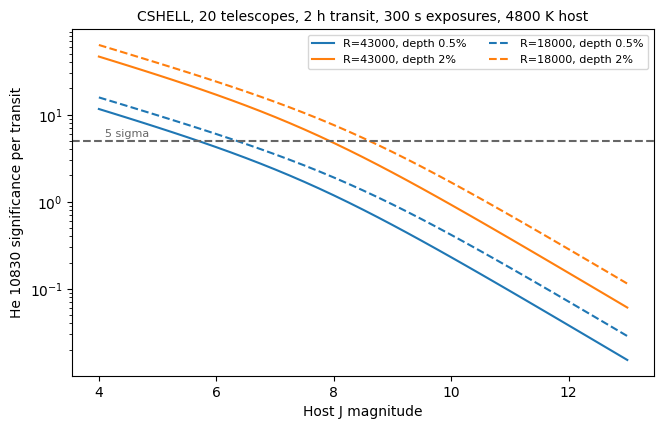

In [4]:
jmags = np.linspace(4, 13, 37)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for mode, ls in (("cshell_r43000", "-"), ("cshell_r18000", "--")):
    etc = he_setup(mode)
    for depth, color in ((0.005, "C0"), (0.02, "C1")):
        s = np.array([significance(etc, Source.blackbody(4800, j, "J"), depth) for j in jmags])
        ax.plot(jmags, s, ls=ls, color=color, label=f"R={etc.instrument.resolving_power:.0f}, depth {100 * depth:g}%")
ax.axhline(5, color="0.4", ls="--"); ax.text(4.1, 5.5, "5 sigma", fontsize=8, color="0.4")
ax.set_yscale("log"); ax.set_xlabel("Host J magnitude"); ax.set_ylabel("He 10830 significance per transit")
ax.legend(ncol=2); ax.set_title(f"CSHELL, {N_TEL} telescopes, 2 h transit, 300 s exposures, 4800 K host")
# R = 18k wins at every magnitude: its resels collect 2.4x more light and it pays no slit loss,
# which outweighs the smaller fraction of the line depth it retains (0.59 vs 0.79).
# Much of the gap is the placeholder slit throughput of 0.5 at R = 43k.

### 4.3 — Why the combiner matters here

CSHELL's 22 e$^-$ read noise and 0.5 e$^-$/s dark current are large. With all fibers combined the
detector terms are paid once per exposure; with independent spectra they are paid $N$ times. Print
the per-transit precision for a J = 9 host at R = 43k for N = 5, 10, 20, 40, 80 telescopes, for
`combine="fiber"` and `"independent"`.

In [5]:
src = Source.blackbody(4800, 9.0, "J")
for combine in ("fiber", "independent"):
    row = []
    for n in (5, 10, 20, 40, 80):
        etc = LFASTETC("cshell_r43000", telescope=Telescope(n, "18um", combine=combine), wavelength_min_nm=1081, wavelength_max_nm=1086)
        row.append(f"N={n}: {100 * precision_per_transit(etc, src)[0]:.2f}%")
    print(f"{combine:12s} " + "  ".join(row))

fiber        N=5: 2.67%  N=10: 1.37%  N=20: 0.73%  N=40: 0.51%  N=80: 0.36%
independent  N=5: 5.81%  N=10: 4.11%  N=20: 2.91%  N=40: 2.05%  N=80: 1.45%


### 4.4 — Paschen-beta accretion monitoring

T Tauri stars in Taurus (140 pc) have J ~ 8 to 12. For a 10% line-flux measurement of Pa-beta
(1282.2 nm, EW ~ 5 A) we need SNR 30 per resel at R = 18k. How long per epoch for J = 8, 10, 12
and 14 (4000 K blackbody) with the nominal array?

In [6]:
pab = LFASTETC("cshell_r18000", n_telescopes=20, wavelength_min_nm=1280, wavelength_max_nm=1284)
t = pab.exptime_vs_mag(Source.blackbody(4000, 0, "J"), [8, 10, 12, 14], snr=30, wavelength=1282.2)
print("  ".join(f"J={m}: {ti:7.0f} s" for m, ti in zip((8, 10, 12, 14), t)))

J=8:      50 s  J=10:     359 s  J=12:    4304 s  J=14:  130465 s


> 🤖 **Ask Jupyter AI:** *Set slit_throughput=1.0 on the R = 43k preset with Instrument.from_preset('cshell_r43000', slit_throughput=1.0) and redo the significance plot: the best case once the slit loss is measured. Then change EXP to 60 s: bright hosts no longer need several reads, but each exposure pays read noise against less signal. Which host magnitude is the break-even point?*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/lfast-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*